# A4 — PINN Digital Twin — Methanol Reactor

## Approach (how this PINN is built)

A **Physics-Informed Neural Network (PINN)** does **not** integrate an ODE with solve_ivp.  
It learns a continuous profile ŷ(z, u) with a neural network, and the ODE is enforced as a **loss term**.

`	ext
Inputs:  u = (T_in, P_in, T_heat, F_in),  z ∈ [0, L]
Network: NN(z, u) → states along the bed
Loss:    L = L_data + λ_phys · L_physics + λ_bc · L_BC
Twin:    query NN at z = 0.2…1.0 m → 8 Excel-style outputs
`

### Build steps in this notebook

1. **Load Methanol Reforming Data.xlsx** — flip the heat-input sign, convert conversion from a fraction to percent.
2. **Define PINN** — NN(z, u) with **hard inlet BC** at z=0 and stoichiometry for CO/H₂.
3. **Learnable kinetics scale** — η(u) so LHHW does not over-convert like the raw physics ODE.
4. **Physics residual** — autodiff dŷ/dz vs mass / energy / Ergun / heat RHS (Torch).
5. **Train** — minimize data match (Excel T, P, Q, X) + light physics residual.
6. **Digital twin** — predict_outputs(T_in, P_in, T_heat, F_in) → 8 outputs + interactive cell.

| Loss | Meaning |
|------|--------|
| **L_data** | Match Excel T at 0.2–1.0 m, P_out, Q, conversion |
| **L_physics** | Autodiff dŷ/dz should equal ODE right-hand side |
| **L_BC** | Soft check that z=0 matches the inlet (also hard-coded) |


**Reaction:** CH₃OH → CO + 2H₂  
**Data:** Methanol Reforming Data.xlsx  

Note: Excel T/Q disagree with strong wall heating at low conversion, so training is **data-dominant** (λ_phys small). Raise N_TRAIN_CASES / EPOCHS for better accuracy.
#
This note means the model's training will prioritize fitting the data (Excel T/Q) over enforcing the physics loss, since the data and physics sometimes disagree (especially at low conversion). As a result, λ_phys is set small, making the PINN behave more like a standard neural net regressor than a physics-driven model in those regions. Raising N_TRAIN_CASES/EPOCHS helps the network fit data better.


## 1. Imports

In [ ]:
from pathlib import Path

# Import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

# Set up file paths 
DATA_FILE = Path("Methanol Reforming Data.xlsx")
# T_heat_C is a per-case plant input from Methanol Reforming Data.xlsx


# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Positions along the reactor bed (meters)
MEASUREMENT_POSITIONS_M = np.array([0.2, 0.4, 0.6, 0.8, 1.0])
P_ATM_BAR = 1.01325  # Atmospheric pressure (bar)

# Input and output columns expected from Excel
INPUT_COLS = ["T_in_C", "P_in_bar_g", "T_heat_C", "F_in_kgmole_h"]
OUTPUT_COLS = [
    "T_0.2m_C", "T_0.4m_C", "T_0.6m_C", "T_0.8m_C", "T_1m_C",
    "P_out_bar_g", "Q_total_kW", "X_overall_pct",
]
TEMP_COLS = ["T_0.2m_C", "T_0.4m_C", "T_0.6m_C", "T_0.8m_C", "T_1m_C"]

# Print some environment info
print("Torch:", torch.__version__, )
print("Data file:", DATA_FILE.resolve())


## 2. Load and clean `Methanol Reforming Data.xlsx`


In [3]:
def load_data(path: Path) -> pd.DataFrame:
    # Load operating cases from Methanol Reforming Data.xlsx (Sheet1).
    raw = pd.read_excel(path, sheet_name=0, header=0, skiprows=[1])  # row1 = units
    n_raw = len(raw)

    data = raw.rename(
        columns={
            "Inlet Temperature (Ti)": "T_in_C",
            "Inlet Pressure (Pi)": "P_in_bar_g",
            "Heating media Temp (Th)": "T_heat_C",
            "Inlet molar flow rate (mi)": "F_in_kgmole_h",
            "Temperature at 0.2m (T1)": "T_0.2m_C",
            "Temperature at 0.4m (T2)": "T_0.4m_C",
            "Temperature at 0.6m (T3)": "T_0.6m_C",
            "Temperature at 0.8m (T4)": "T_0.8m_C",
            "Temperature at 1m (T5)": "T_1m_C",
            "Pressure at 1m (P5)": "P_out_bar_g",
        }
    )

    # Excel segment heat flows are negative for heat into the reactor → flip and sum.
    # Ensure numeric dtypes after dropping the Excel units row
    for _col in [
        "T_in_C", "P_in_bar_g", "T_heat_C", "F_in_kgmole_h",
        "T_0.2m_C", "T_0.4m_C", "T_0.6m_C", "T_0.8m_C", "T_1m_C", "P_out_bar_g",
        "Conversion at 1m (X-5)",
    ]:
        if _col in data.columns:
            data[_col] = pd.to_numeric(data[_col], errors="coerce")
    for _col in [c for c in data.columns if str(c).startswith("Heat flow")]:
        data[_col] = pd.to_numeric(data[_col], errors="coerce")

    heat_cols = [c for c in data.columns if str(c).startswith("Heat flow")]
    data["Q_total_kW"] = -data[heat_cols].sum(axis=1)

    # Excel stores conversion as a fraction → percent.
    data["X_overall_pct"] = data["Conversion at 1m (X-5)"] * 100.0

    print(f"Total rows in file          : {n_raw}")

    ok = (
        data["X_overall_pct"].between(0, 100)
        & data["Q_total_kW"].between(-50, 50)
        & data[["T_in_C", "P_in_bar_g", "T_heat_C", "F_in_kgmole_h"]].notna().all(axis=1)
    )
    cleaned = data.loc[ok].reset_index(drop=True)
    print(f"Valid rows                  : {len(cleaned)}")
    return cleaned
df = load_data(DATA_FILE)  # Main dataframe; full cleaned dataset
# Split dataset into training and test sets (80%/20%)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
train_df = train_df.reset_index(drop=True)  # Reset indices after split
test_df = test_df.reset_index(drop=True)
print(f"Train={len(train_df)}  Test={len(test_df)}")
display(df[INPUT_COLS + OUTPUT_COLS].head())  # Show a preview of the processed data


Total rows in file          : 3480
Valid rows                  : 3214
Train=2571  Test=643


,T_in_C,P_in_bar_g,T_heat_C,F_in_kgmole_h,T_0.2m_C,T_0.4m_C,T_0.6m_C,T_0.8m_C,T_1m_C,P_out_bar_g,Q_total_kW,X_overall_pct
0,200,0.4,250,0.10,113.6,125.2,135.9,145.5,154.1,0.36910,0.7511,30.862860
1,200,0.4,250,0.35,115.0,114.7,118.4,122.7,126.8,0.28980,0.8192,13.111300
2,200,0.4,250,0.60,120.2,116.4,117.7,120.1,122.8,0.15300,0.9237,10.286000
3,200,0.4,250,0.85,124.4,118.9,118.9,120.4,122.5,-0.06318,1.0330,9.061224
4,200,0.4,250,1.10,127.8,121.3,120.4,121.3,123.1,-0.43840,1.1335,8.302036


## 3. Reactor constants and scaling

PINNs need scaled inputs/outputs so residuals stay numerically stable.

Thermo (same as A3 / A2 / Parallel):
- **R** = `1.987` kcal/(kgmole·K)
- **ΔH(25 °C)** = `2.2e+04` kcal/kgmole
- **ΔH(T)** = ΔH(25°C) + ΔCp·(T − 25)  (temperature-dependent)


In [4]:
# --- Thermo constants (same as A3 / A2 / Parallel) ---
R_kcal = 1.987                 # gas constant [kcal/(kgmole·K)]
delta_H_ref_kcal = 2.2e4       # reaction heat at 25 °C [kcal/kgmole]
T_ref_C = 25.0                 # reference temperature [°C]

# Convert to SI for physics residual: kcal/kgmole -> J/mol
KCAL_PER_KGMOLE_TO_J_PER_MOL = 4184.0 / 1000.0
R = R_kcal * KCAL_PER_KGMOLE_TO_J_PER_MOL                      # [J/(mol·K)]
delta_H_ref = delta_H_ref_kcal * KCAL_PER_KGMOLE_TO_J_PER_MOL  # [J/mol] at 25 °C

# Reactor inner diameter (meters)
D = 0.1

# Reactor length (meters)
L = 1.0

# Jacket-side coefficient h_o [W/(m^2·K)]. The residual uses h_heat = U(F_in).
h_o = 115.0

# External heat source temperature (Celsius)
# T_heat_C is a per-case plant input

# Reactor porosity (fraction of reactor volume that is void)
epsilon = 0.33

# Catalyst particle diameter (meters)
dp = 1.0e-3

# Reactor cross-sectional area (m^2)
Ac = np.pi * D**2 / 4

# Reactor inner perimeter (meters)
perimeter = np.pi * D

# Molar mass (kg/mol) for each component:
MW_CH3OH = 32.04e-3   # Methanol
MW_CO = 28.01e-3      # Carbon monoxide
MW_H2 = 2.016e-3      # Hydrogen

# Molar heat capacities (J/(mol·K)) for each component
Cp_CH3OH = 43.0
Cp_CO = 29.0
Cp_H2 = 29.0

# ΔCp for reaction CH3OH -> CO + 2H2  [J/(mol·K)]
delta_Cp = Cp_CO + 2.0 * Cp_H2 - Cp_CH3OH

# Arrhenius pre-factor for overall methanol reaction
A_kinetic = 7.0e10

# Activation energy [kcal/kgmole]; Arrhenius uses R_kcal
E_kinetic = 19120.0

# Arrhenius pre-factor for CO adsorption
A_CO = 1.0e7

# CO adsorption energy [kcal/kgmole]; Arrhenius uses R_kcal
E_CO = 6036.8



mu_gas = 2.0e-5          # Gas viscosity [Pa·s]
k_gas = 0.035            # Gas thermal conductivity [W/(m·K)]


def bed_side_htc(F_in_mol_s):
    # Specchia bed-side wall coefficient h_i [W/(m²·°C)]
    # Works with Python floats and torch tensors (PINN residual path).
    mass_flux = F_in_mol_s * MW_CH3OH / Ac
    if torch.is_tensor(mass_flux):
        Re_p = torch.clamp(dp * mass_flux / mu_gas, min=1e-12)
        Nu_w = 2.0 * epsilon + 0.0835 * (Re_p ** 0.91)
        return Nu_w * k_gas / dp
    Re_p = max(dp * mass_flux / mu_gas, 1e-12)
    Nu_w = 2.0 * epsilon + 0.0835 * (Re_p ** 0.91)
    return Nu_w * k_gas / dp


def overall_U(F_in_mol_s):
    # Overall wall coefficient. h_heat = U, from the inlet methanol flow.
    # If a batch tensor is passed, use a single inlet value (U is constant along z).
    if torch.is_tensor(F_in_mol_s):
        F_use = F_in_mol_s.reshape(-1)[0]
        h_i = bed_side_htc(F_use)
        return 1.0 / (1.0 / h_o + 1.0 / h_i)
    h_i = bed_side_htc(F_in_mol_s)
    return 1.0 / (1.0 / h_o + 1.0 / h_i)

def reaction_enthalpy(T_C):
    # Temperature-dependent ΔH [J/mol]; works with float or torch tensor
    # ΔH(T) = ΔH(25°C) + ΔCp*(T-25)
    return delta_H_ref + delta_Cp * (T_C - T_ref_C)


# Scaling references from training data
T_REF = float(train_df["T_in_C"].mean())
P_REF_BAR = float(train_df["P_in_bar_g"].mean() + P_ATM_BAR)
F_REF = float((train_df["F_in_kgmole_h"] * 1000.0 / 3600.0).mean())
T_HEAT_REF = float(train_df["T_heat_C"].mean())
Q_REF = max(float(train_df["Q_total_kW"].abs().mean()), 1.0)

# Physical band for *axial bed* temperatures (Excel measurement points)
_T_ax = train_df[TEMP_COLS].to_numpy(dtype=float)
T_BED_LO = float(max(np.nanmin(_T_ax) - 5.0, 0.0))
T_BED_HI = float(np.nanmax(_T_ax) + 5.0)
T_DATA_SCALE = float(max(np.nanstd(_T_ax), 20.0))
# Max gauge pressure drop seen in data (Pa) — keep Ergun-ish but bounded
_dp_bar = (train_df["P_in_bar_g"] - train_df["P_out_bar_g"]).clip(lower=0)
DP_MAX_PA = float(max(_dp_bar.quantile(0.99), 0.05) * 1.0e5)
Q_MAX = float(max(train_df["Q_total_kW"].abs().quantile(0.99), Q_REF))

print(f"R = {R_kcal} kcal/(kgmole·K)  ->  {R:.6f} J/(mol·K)")
print(f"ΔH(25°C) = {delta_H_ref_kcal:.3e} kcal/kgmole  ->  {delta_H_ref:.3e} J/mol")
print(f"ΔCp = {delta_Cp:.2f} J/(mol·K)")
print(f"T_REF={T_REF:.1f} °C, P_REF={P_REF_BAR:.3f} bar, F_REF={F_REF:.4e} mol/s")
print(f"Axial T band (1–99%): [{T_BED_LO:.1f}, {T_BED_HI:.1f}] °C")
print(f"T_DATA_SCALE={T_DATA_SCALE:.1f} °C | DP_MAX={DP_MAX_PA/1e5:.3f} bar | Q_MAX={Q_MAX:.2f} kW")


R = 1.987 kcal/(kgmole·K)  ->  8.313608 J/(mol·K)
ΔH(25°C) = 2.200e+04 kcal/kgmole  ->  9.205e+04 J/mol
ΔCp = 44.00 J/(mol·K)
T_REF=352.6 °C, P_REF=3.506 bar, F_REF=3.0278e-01 mol/s
Axial T band (1–99%): [108.0, 390.2] °C
T_DATA_SCALE=39.6 °C | DP_MAX=1.931 bar | Q_MAX=30.00 kW


## 4. PINN network

- Hard inlet BC at `z=0`
- Axial T: 5 Excel nodes from `u`; `T_0.4` locked between `T_0.2` and `T_0.6`
- **Q from direct `q_net(u)`** (fixes near-zero heat duty)
- At prediction time, if `T_1m ≥ T_0.2`, apply a light isotonic smooth so early-bed dips disappear while the outlet is hotter


In [5]:
class ReactorPINN(nn.Module):
    """PINN: T_0.4 between neighbors + direct Q(u)."""

    def __init__(self, hidden=128, depth=4):
        super().__init__()
        layers = [nn.Linear(5, hidden), nn.Tanh()]
        for _ in range(depth - 1):
            layers += [nn.Linear(hidden, hidden), nn.Tanh()]
        layers.append(nn.Linear(hidden, 2))  # F, P
        self.net = nn.Sequential(*layers)

        self.t_net = nn.Sequential(
            nn.Linear(4, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 5),
        )
        self.q_net = nn.Sequential(
            nn.Linear(4, 32), nn.Tanh(), nn.Linear(32, 1),
        )
        self.eta_net = nn.Sequential(
            nn.Linear(4, 32), nn.Tanh(), nn.Linear(32, 1),
        )
        with torch.no_grad():
            self.eta_net[-1].bias.fill_(-4.605170186)
            self.net[-1].bias.zero_()
            self.t_net[-1].bias.zero_()
            self.t_net[-1].bias[:] = torch.tensor([-0.5, 0.0, -0.2, -0.1, 0.0])
            self.q_net[-1].bias.fill_(0.541324854)

    def eta(self, u_n):
        return torch.nn.functional.softplus(self.eta_net(u_n)) + 1e-12

    def axial_T_nodes(self, u_n):
        band = T_BED_HI - T_BED_LO
        r = self.t_net(u_n)
        T02 = T_BED_LO + band * torch.sigmoid(r[:, 0:1])
        T06 = T_BED_LO + band * torch.sigmoid(r[:, 2:3])
        alpha = torch.sigmoid(r[:, 1:2])
        T04 = T02 + (T06 - T02) * alpha  # between T02 and T06
        T08 = T_BED_LO + band * torch.sigmoid(r[:, 3:4])
        T10 = T_BED_LO + band * torch.sigmoid(r[:, 4:5])
        return torch.cat([T02, T04, T06, T08, T10], dim=1)

    def Q_total(self, u_n):
        return torch.clamp(
            torch.nn.functional.softplus(self.q_net(u_n)) * Q_REF,
            min=0.0, max=Q_MAX * 1.2,
        )

    def _axial_T(self, z_n, T_in, u_n):
        T_nodes5 = self.axial_T_nodes(u_n)
        T_nodes = torch.cat([T_in, T_nodes5], dim=1)
        z_nodes = torch.tensor(
            [0.0, 0.2, 0.4, 0.6, 0.8, 1.0], dtype=T_nodes.dtype, device=T_nodes.device
        )
        z_n = torch.clamp(z_n, 0.0, 1.0)
        idxs = torch.clamp(torch.bucketize(z_n.reshape(-1), z_nodes) - 1, min=0, max=4)
        i0, i1 = idxs, idxs + 1
        z0 = z_nodes[i0].view(-1, 1)
        z1 = z_nodes[i1].view(-1, 1)
        N = T_nodes.shape[0]
        ar = torch.arange(N, device=T_nodes.device)
        t0 = T_nodes[ar, i0].view(-1, 1)
        t1 = T_nodes[ar, i1].view(-1, 1)
        w = (z_n - z0) / (z1 - z0 + 1e-12)
        T_C = (1.0 - w) * t0 + w * t1
        return torch.clamp(T_C, min=0.0, max=float(T_BED_HI) + 30.0), T_nodes5

    def forward(self, z, u_phys):
        T_in = u_phys[:, 0:1]
        P_in_bar_g = u_phys[:, 1:2]
        T_heat = u_phys[:, 2:3]
        F_in_kgmole_h = u_phys[:, 3:4]
        F_in = F_in_kgmole_h * 1000.0 / 3600.0
        P_in_Pa = (P_in_bar_g + P_ATM_BAR) * 1.0e5
        z_n = torch.clamp(z / L, min=0.0, max=1.0)
        u_n = torch.cat(
            [
                T_in / T_REF,
                (P_in_bar_g + P_ATM_BAR) / P_REF_BAR,
                T_heat / T_HEAT_REF,
                F_in / F_REF,
            ],
            dim=1,
        )
        raw = self.net(torch.cat([z_n, u_n], dim=1))
        methanol_consumed = z_n * torch.nn.functional.softplus(raw[:, 0:1]) * F_in
        methanol_consumed = torch.clamp(methanol_consumed, max=0.999 * F_in)
        F_CH3OH = torch.clamp(F_in - methanol_consumed, min=1e-12)
        T_C, T_nodes5 = self._axial_T(z_n, T_in, u_n)
        P = torch.clamp(P_in_Pa - z_n * torch.sigmoid(raw[:, 1:2]) * DP_MAX_PA, min=5.0e3)
        Q_kW = z_n * self.Q_total(u_n)
        return {
            "F_CH3OH": F_CH3OH,
            "F_CO": methanol_consumed,
            "F_H2": 2.0 * methanol_consumed,
            "T_C": T_C,
            "P": P,
            "Q_kW": Q_kW,
            "F_in": F_in,
            "T_heat_C": T_heat,
            "u_n": u_n,
            "T_nodes5": T_nodes5,
        }


model = ReactorPINN()
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("T_0.4 between neighbors | Q=softplus(q_net(u))*Q_REF")


ReactorPINN(
  (net): Sequential(
    (0): Linear(in_features=5, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Tanh()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): Tanh()
    (6): Linear(in_features=128, out_features=128, bias=True)
    (7): Tanh()
    (8): Linear(in_features=128, out_features=2, bias=True)
  )
  (t_net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=5, bias=True)
  )
  (q_net): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
  (eta_net): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)
Parameters: 55753
T_0.4 betwe

## 5. Physics residual (ODE RHS in Torch)

Autodiff gives `dŷ/dz`. Physics loss penalizes mismatch with mass / energy / pressure / heat ODEs.
#
In this step, we define the physics-based residual that represents the right-hand side (RHS) of the ordinary differential equations (ODEs) using PyTorch operations. Autodifferentiation will be used to compute the derivatives of the predicted states with respect to the reactor position, and the physics loss will penalize any mismatch between these derivatives and the corresponding ODEs for mass, energy, pressure, and heat transfer.

In [6]:
def reaction_rate_torch(T_C, P, F_CH3OH, F_CO, F_H2, eta):
    # Convert temperature to Kelvin
    T_abs = T_C + 273.15

    # Total flow to avoid zero division
    F_total = torch.clamp(F_CH3OH + F_CO + F_H2, min=1e-12)

    # Compute total concentration (ideal gas law)
    C_total = P / (R * T_abs) / 1000.0  # kgmole/m³

    # Molar fractions times total conc. give partial concentrations
    C_M = (F_CH3OH / F_total) * C_total
    C_CO = (F_CO / F_total) * C_total

    # Reaction numerator (Arrhenius law). E and R_kcal are in kcal/kgmole.
    num = A_kinetic * torch.exp(-E_kinetic / (R_kcal * T_abs)) * C_M

    # Reaction denominator (CO inhibition)
    den = 1.0 + A_CO * torch.exp(-E_CO / (R_kcal * T_abs)) * C_CO

    # mol/(m³·s), scaled by eta, then clamped to keep PINN physics loss finite
    r = eta * (num / den) * 1000.0
    return torch.clamp(r, min=0.0, max=500.0)


def ode_rhs(states, eta):
    # Unpack state variables from dictionary
    F_CH3OH = states["F_CH3OH"]  # methanol flow
    F_CO = states["F_CO"]        # CO flow
    F_H2 = states["F_H2"]        # H2 flow
    T_C = states["T_C"]          # Temperature (C)
    P = states["P"]              # Pressure (Pa)

    # Compute reaction rate (arrhenius law, inhibition, effectiveness)
    r = reaction_rate_torch(T_C, P, F_CH3OH, F_CO, F_H2, eta)
    rpl = r * Ac                 # Reaction per length (mol/s/m)

    # Compute heat transferred from wall to gas
    h_heat = overall_U(states["F_in"])  # revised physics: U from inlet methanol flow
    q_transfer = h_heat * perimeter * (states["T_heat_C"] - T_C)
    # Get heat capacity flow (avoid 0)
    Cp_flow = torch.clamp(
        F_CH3OH * Cp_CH3OH + F_CO * Cp_CO + F_H2 * Cp_H2, min=1e-9
    )
    # Energy balance: temperature gradient wrt z
    delta_H_T = reaction_enthalpy(T_C)  # [J/mol] at local T (torch-safe)
    dT = (q_transfer - delta_H_T * rpl) / Cp_flow

    F_total = torch.clamp(F_CH3OH + F_CO + F_H2, min=1e-12)  # total molar flow
    mass_flow = F_CH3OH * MW_CH3OH + F_CO * MW_CO + F_H2 * MW_H2  # total mass flow
    MW_mix = mass_flow / F_total  # average molecular weight
    T_abs = T_C + 273.15  # convert C to K
    rho = P * MW_mix / (R * T_abs)  # gas density
    velocity = mass_flow / torch.clamp(rho * Ac, min=1e-12)  # mixture velocity
    mu = mu_gas  # constant gas viscosity
    viscous = 150.0 * mu * (1.0 - epsilon) ** 2 / (epsilon ** 3 * dp ** 2) * velocity  # viscous term
    inertial = 1.75 * rho * (1.0 - epsilon) / (epsilon ** 3 * dp) * velocity ** 2  # inertial term
    dP = -(viscous + inertial)  # pressure drop
    dQ_kW = q_transfer / 1000.0  # heat in kW

    return {
        "dF_CH3OH": -rpl,
        "dF_CO": rpl,
        "dF_H2": 2.0 * rpl,
        "dT_C": dT,
        "dP": dP,
        "dQ_kW": dQ_kW,
    }


def autodiff_dz(states, z):
    # Compute dz (derivative with respect to z) for all main state variables using autograd
    grads = {}
    for key in ["F_CH3OH", "F_CO", "F_H2", "T_C", "P", "Q_kW"]:
        # Get gradient of this state with respect to z
        g = torch.autograd.grad(
            states[key], z, grad_outputs=torch.ones_like(states[key]),
            create_graph=True, retain_graph=True,
        )[0]
        grads[key] = g
    # Return gradients for all keys
    return grads


print("Physics residual helpers ready.")


Physics residual helpers ready.


## 6. Batch builder + PINN loss

For each operating case we sample:
- collocation `z` points → physics residual
- measurement `z` points → data loss vs Excel
#
**Description of this step:**
# 
In this step, we construct the batch processing logic and define
the physics-informed neural network (PINN) loss function for each operating case.
Specifically, for each set of input conditions (operating case), we:
- Sample collocation points along the reactor length where we will enforce the governing physics equations by minimizing the residuals (physics loss)
- Evaluate the model at measurement locations where real or simulated data is available, adding a data loss term by comparing model predictions to given values (e.g., from Excel)
These components are combined in a loss function that enables the PINN to learn both from physics constraints and available measurement data.



In [7]:
def make_case_tensors(row):
    u = torch.tensor(
        [[row["T_in_C"], row["P_in_bar_g"], row["T_heat_C"], row["F_in_kgmole_h"]]],
        dtype=torch.float32,
    )
    y_data = torch.tensor([[row[c] for c in OUTPUT_COLS]], dtype=torch.float32)
    return u, y_data


def _u_n_from_u(u):
    return torch.cat(
        [
            u[:, 0:1] / T_REF,
            (u[:, 1:2] + P_ATM_BAR) / P_REF_BAR,
            u[:, 2:3] / T_HEAT_REF,
            (u[:, 3:4] * 1000.0 / 3600.0) / F_REF,
        ],
        dim=1,
    )


def pinn_loss_for_case(model, u, y_data, n_colloc=16):
    z_col = torch.rand(n_colloc, 1) * L
    z_col.requires_grad_(True)
    states = model(z_col, u.repeat(n_colloc, 1))
    eta = model.eta(states["u_n"])
    rhs = ode_rhs(states, eta)
    d_pred = autodiff_dz(states, z_col)

    def _term(pred, target, scale):
        return torch.mean(torch.clamp(((pred - target) / scale) ** 2, max=1.0e3))

    L_phys = (
        _term(d_pred["F_CH3OH"], rhs["dF_CH3OH"], F_REF)
        + _term(d_pred["F_CO"], rhs["dF_CO"], F_REF)
        + _term(d_pred["F_H2"], rhs["dF_H2"], F_REF)
        + _term(d_pred["P"], rhs["dP"], 1e4)
    )
    L_phys = torch.nan_to_num(L_phys, nan=1.0e3, posinf=1.0e3, neginf=1.0e3)

    u_n = _u_n_from_u(u)
    T_pred = model.axial_T_nodes(u_n).view(-1)
    T_true = y_data[0, 0:5]
    t_w = torch.tensor([2.5, 3.0, 2.0, 1.5, 2.5], dtype=torch.float32)
    L_T = torch.mean(t_w * ((T_pred - T_true) / T_DATA_SCALE) ** 2)
    dT_pred = T_pred[1:] - T_pred[:-1]
    dT_true = T_true[1:] - T_true[:-1]
    L_dT = torch.mean(((dT_pred - dT_true) / T_DATA_SCALE) ** 2)
    seg_w = torch.tensor([5.0, 2.0, 1.0, 1.0], dtype=torch.float32)
    L_dir = torch.mean(seg_w * torch.relu(-dT_pred * torch.sign(dT_true + 1e-6)) / T_DATA_SCALE)

    Q_pred = model.Q_total(u_n).view(-1)
    L_Q = ((Q_pred - y_data[0, 6]) / max(Q_REF, 1.0)) ** 2

    z_L = torch.tensor([[L]], dtype=torch.float32, requires_grad=True)
    st_L = model(z_L, u)
    P_out_bar_g = st_L["P"] / 1.0e5 - P_ATM_BAR
    X_pct = (st_L["F_in"] - st_L["F_CH3OH"]) / st_L["F_in"] * 100.0

    L_data = (
        12.0 * L_T + 5.0 * L_dT + 8.0 * L_dir + 8.0 * L_Q.mean()
        + ((P_out_bar_g - y_data[0, 5]) / 0.5) ** 2
        + ((X_pct - y_data[0, 7]) / 10.0) ** 2
    )

    z0 = torch.zeros(1, 1, requires_grad=True)
    st0 = model(z0, u)
    L_bc = (
        ((st0["T_C"] - u[0, 0]) / T_DATA_SCALE) ** 2
        + (st0["F_CO"] / F_REF) ** 2
        + (st0["Q_kW"] / max(Q_REF, 1.0)) ** 2
    ).mean()

    loss = torch.nan_to_num(L_data.mean() + 0.001 * L_phys + 0.05 * L_bc, nan=1e3, posinf=1e3)
    return loss, {
        "L_data": float(L_data.detach().mean()),
        "L_phys": float(L_phys.detach()),
        "L_bc": float(L_bc.detach()),
        "L_T": float(L_T.detach()),
        "L_dT": float(L_dT.detach()),
    }


print("Loss ready.")


Loss ready.


## 7. Train the PINN

Trains on a subset of operating cases for speed. Increase `N_TRAIN_CASES` / `EPOCHS` for higher accuracy.

Train mix: rising 0.2→1.0 = 150, other = 100
Training PINN on 250 cases × 200 epochs...
epoch    1 | loss=1.5475e+02 | L_T=6.219e+00 data=1.477e+02 phys=5.623e+01
epoch   20 | loss=8.2074e+01 | L_T=2.257e+00 data=7.864e+01 phys=1.511e+01
epoch   40 | loss=7.0194e+01 | L_T=1.809e+00 data=6.713e+01 phys=2.045e+01
epoch   60 | loss=6.4784e+01 | L_T=1.650e+00 data=6.091e+01 phys=1.426e+01
epoch   80 | loss=5.9031e+01 | L_T=1.462e+00 data=5.536e+01 phys=1.447e+01
epoch  100 | loss=5.3071e+01 | L_T=1.315e+00 data=5.130e+01 phys=1.440e+01
epoch  120 | loss=4.9042e+01 | L_T=1.159e+00 data=4.784e+01 phys=1.576e+01
epoch  140 | loss=4.7523e+01 | L_T=1.069e+00 data=4.576e+01 phys=1.384e+01
epoch  160 | loss=4.5117e+01 | L_T=1.025e+00 data=4.463e+01 phys=1.299e+01
epoch  180 | loss=4.7326e+01 | L_T=1.010e+00 data=4.422e+01 phys=1.304e+01
epoch  200 | loss=4.5537e+01 | L_T=1.005e+00 data=4.414e+01 phys=1.421e+01
Restored best weights by L_T=1.0054e+00


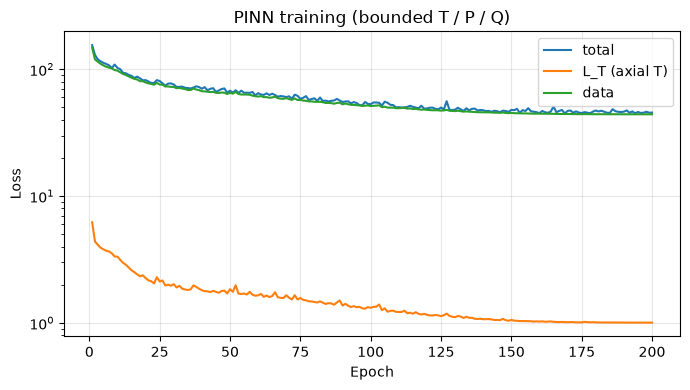

Training finished.


In [8]:
N_TRAIN_CASES = 250
EPOCHS = 200
BATCH_CASES = 20
N_COLLOC = 12

# Prefer cases where bed heats 0.2→1.0 (matches plant heating / interactive defaults)
_rising = train_df["T_1m_C"] >= train_df["T_0.2m_C"]
_n_rise = int(0.6 * min(N_TRAIN_CASES, len(train_df)))
_n_other = min(N_TRAIN_CASES, len(train_df)) - _n_rise
_rise_df = train_df.loc[_rising].sample(n=min(_n_rise, int(_rising.sum())), random_state=42)
_other_df = train_df.loc[~_rising].sample(n=min(_n_other, int((~_rising).sum())), random_state=42)
train_cases = pd.concat([_rise_df, _other_df], ignore_index=True).sample(frac=1.0, random_state=42).reset_index(drop=True)
case_data = [make_case_tensors(row) for _, row in train_cases.iterrows()]
print(f"Train mix: rising 0.2→1.0 = {int((_rise_df.shape[0]))}, other = {int((_other_df.shape[0]))}")

model = ReactorPINN()  # always re-init after architecture changes
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
history = []
best_lt = float("inf")
best_state = None

print(f"Training PINN on {len(case_data)} cases × {EPOCHS} epochs...")
for epoch in range(1, EPOCHS + 1):
    model.train()
    idx = np.random.permutation(len(case_data))
    total = 0.0
    n_batches = 0
    sum_parts = {"L_data": 0.0, "L_phys": 0.0, "L_bc": 0.0, "L_T": 0.0, "L_dT": 0.0}

    for s in range(0, len(idx), BATCH_CASES):
        batch_ids = idx[s : s + BATCH_CASES]
        optimizer.zero_grad()
        loss_batch = 0.0
        for j in batch_ids:
            u, y = case_data[j]
            loss_j, parts = pinn_loss_for_case(model, u, y, n_colloc=N_COLLOC)
            loss_batch = loss_batch + loss_j
            for k in sum_parts:
                sum_parts[k] += parts.get(k, 0.0)
        loss_batch = loss_batch / len(batch_ids)
        if not torch.isfinite(loss_batch):
            continue
        loss_batch.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total += float(loss_batch.detach())
        n_batches += 1

    scheduler.step()
    scale = 1.0 / max(n_batches * BATCH_CASES, 1)
    rec = {
        "epoch": epoch,
        "loss": total / max(n_batches, 1),
        "L_data": sum_parts["L_data"] * scale,
        "L_phys": sum_parts["L_phys"] * scale,
        "L_bc": sum_parts["L_bc"] * scale,
        "L_T": sum_parts["L_T"] * scale,
    }
    history.append(rec)
    if rec["L_T"] < best_lt:
        best_lt = rec["L_T"]
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    if epoch % 20 == 0 or epoch == 1:
        print(
            f"epoch {epoch:4d} | loss={rec['loss']:.4e} | "
            f"L_T={rec['L_T']:.3e} data={rec['L_data']:.3e} phys={rec['L_phys']:.3e}"
        )

if best_state is not None:
    model.load_state_dict(best_state)
    print(f"Restored best weights by L_T={best_lt:.4e}")

hist_df = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist_df["epoch"], hist_df["loss"], label="total")
ax.plot(hist_df["epoch"], hist_df["L_T"], label="L_T (axial T)")
ax.plot(hist_df["epoch"], hist_df["L_data"], label="data")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_yscale("log")
ax.set_title("PINN training (bounded T / P / Q)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("Training finished.")


## 8. Residual correction (boost R²) + digital twin prediction

PINN alone still underfits Excel T/Q (physics–data clash).  
Train Parallel-style residual on train cases:

```text
ŷ = clip(y_pinn + r̂_ML(u))
```


In [ ]:
def _isotonic_rising(ts):
    """If outlet >= first point, remove early dips via cumulative max."""
    ts = np.asarray(ts, dtype=float).copy()
    if ts[-1] + 1e-9 < ts[0]:
        return ts
    return np.maximum.accumulate(ts)


def clip_hybrid(y, P_in_bar_g):
    out = np.asarray(y, dtype=float).copy()
    out[0:5] = np.clip(out[0:5], 0.0, 800.0)
    out[5] = min(float(out[5]), float(P_in_bar_g) - 1e-6)
    out[7] = np.clip(out[7], 0.0, 100.0)
    return out


@torch.no_grad()
def predict_pinn_only(T_in_C, P_in_bar_g, T_heat_C, F_in_kgmole_h, n_profile=80):
    """Raw PINN outputs (before residual)."""
    model.eval()
    u = torch.tensor(
        [[float(T_in_C), float(P_in_bar_g), float(T_heat_C), float(F_in_kgmole_h)]],
        dtype=torch.float32,
    )
    u_n = torch.cat(
        [
            u[:, 0:1] / T_REF,
            (u[:, 1:2] + P_ATM_BAR) / P_REF_BAR,
            u[:, 2:3] / T_HEAT_REF,
            (u[:, 3:4] * 1000.0 / 3600.0) / F_REF,
        ],
        dim=1,
    )
    T_axial = model.axial_T_nodes(u_n).cpu().numpy().reshape(-1)
    T_axial = _isotonic_rising(T_axial)
    T_axial = np.clip(T_axial, 0.0, 800.0)

    z_L = torch.tensor([[L]], dtype=torch.float32)
    st_L = model(z_L, u)
    P_out_bar_g = float(np.clip(float(st_L["P"].cpu() / 1e5 - P_ATM_BAR), -0.5, float(P_in_bar_g) - 1e-4))
    Q_kW = float(np.clip(float(model.Q_total(u_n).cpu()), 0.0, Q_MAX * 1.5))
    X_pct = float(np.clip(float(((st_L["F_in"] - st_L["F_CH3OH"]) / st_L["F_in"] * 100.0).cpu()), 0.0, 100.0))
    eta = float(model.eta(u_n).cpu())

    z_nodes = np.array([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
    T_nodes = np.concatenate([[float(T_in_C)], T_axial])
    z_prof = np.linspace(0.0, L, n_profile)
    T_profile = np.interp(z_prof, z_nodes, T_nodes)

    y = np.array(
        [T_axial[0], T_axial[1], T_axial[2], T_axial[3], T_axial[4], P_out_bar_g, Q_kW, X_pct],
        dtype=float,
    )
    return {
        "y": y,
        "eta": eta,
        "z_m": z_prof,
        "T_profile_C": T_profile,
    }


# --- train residual on PINN train cases (use full train_df sample for coverage) ---
_res_df = train_df.sample(n=min(800, len(train_df)), random_state=42).reset_index(drop=True)
print(f"Building PINN residuals on {len(_res_df)} train cases...")
Y_pinn_rows, U_rows, Y_ex_rows = [], [], []
n_fail = 0
for k, row in _res_df.iterrows():
    try:
        base = predict_pinn_only(row["T_in_C"], row["P_in_bar_g"], row["T_heat_C"], row["F_in_kgmole_h"])
        y = base["y"]
        if not np.isfinite(y).all():
            n_fail += 1
            continue
        Y_pinn_rows.append(y)
        U_rows.append([row[c] for c in INPUT_COLS])
        Y_ex_rows.append([row[c] for c in OUTPUT_COLS])
    except Exception:
        n_fail += 1
    if (k + 1) % 100 == 0 or (k + 1) == len(_res_df):
        print(f"  {k+1}/{len(_res_df)} (ok={len(Y_pinn_rows)}, fail={n_fail})")

Y_pinn_train = np.asarray(Y_pinn_rows, dtype=float)
U_train_res = np.asarray(U_rows, dtype=float)
Y_ex_train = np.asarray(Y_ex_rows, dtype=float)
R_train = Y_ex_train - Y_pinn_train

residual_model = MultiOutputRegressor(
    HistGradientBoostingRegressor(
        max_depth=6,
        learning_rate=0.08,
        max_iter=250,
        l2_regularization=0.1,
        random_state=42,
    )
)
residual_model.fit(U_train_res, R_train)
print(
    f"PINN residual trained | mean |r|: {np.mean(np.abs(R_train), axis=0).round(3)}"
)


def predict_outputs(T_in_C, P_in_bar_g, T_heat_C, F_in_kgmole_h, n_profile=80):
    """PINN + residual twin: ŷ = clip(y_pinn + r̂(u))."""
    base = predict_pinn_only(T_in_C, P_in_bar_g, T_heat_C, F_in_kgmole_h, n_profile=n_profile)
    y_pinn = base["y"]
    u = np.array([[T_in_C, P_in_bar_g, T_heat_C, F_in_kgmole_h]], dtype=float)
    r_hat = residual_model.predict(u)[0]
    y_hat = clip_hybrid(y_pinn + r_hat, P_in_bar_g=P_in_bar_g)
    # Keep axial T points consistent after residual (and isotonic if rising)
    T_pts = _isotonic_rising(y_hat[0:5]) if y_hat[4] >= y_hat[0] - 1e-9 else y_hat[0:5]
    y_hat[0:5] = np.clip(T_pts, 0.0, 800.0)

    z_nodes = np.array([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
    T_nodes = np.concatenate([[float(T_in_C)], y_hat[0:5]])
    T_profile = np.interp(base["z_m"], z_nodes, T_nodes)

    out = {c: float(y_hat[i]) for i, c in enumerate(OUTPUT_COLS)}
    out["eta"] = base["eta"]
    out["z_m"] = base["z_m"]
    out["T_profile_C"] = T_profile
    out["y_pinn"] = {c: float(y_pinn[i]) for i, c in enumerate(OUTPUT_COLS)}
    out["r_hat"] = {c: float(r_hat[i]) for i, c in enumerate(OUTPUT_COLS)}
    return out


demo = train_cases.iloc[0]
pred = predict_outputs(demo["T_in_C"], demo["P_in_bar_g"], demo["T_heat_C"], demo["F_in_kgmole_h"])
smoke = pd.DataFrame({
    "Output": OUTPUT_COLS,
    "Excel": [demo[c] for c in OUTPUT_COLS],
    "PINN only": [pred["y_pinn"][c] for c in OUTPUT_COLS],
    "PINN + residual": [pred[c] for c in OUTPUT_COLS],
})
smoke["Abs error"] = (smoke["PINN + residual"] - smoke["Excel"]).abs()
print(f"Smoke test (eta≈{pred['eta']:.3e}):")
print("  T profile: " + ", ".join(f"{c}={pred[c]:.1f}" for c in TEMP_COLS))
display(smoke.round(4))


## 9. Validate on held-out test cases

Reports **PINN only** vs **PINN + residual** MAE / R².


In [ ]:
N_TEST_EVAL = min(120, len(test_df))
eval_df = test_df.head(N_TEST_EVAL)

n_bad_weights = sum(
    int(torch.isnan(p).any() or torch.isinf(p).any()) for p in model.parameters()
)
if n_bad_weights:
    raise RuntimeError(
        f"PINN weights contain NaN/Inf in {n_bad_weights} tensors. "
        "Re-run Section 4 then Section 7 before validating."
    )

Y_true, Y_pinn, Y_hyb = [], [], []
n_skip = 0
for _, row in eval_df.iterrows():
    try:
        base = predict_pinn_only(row["T_in_C"], row["P_in_bar_g"], row["T_heat_C"], row["F_in_kgmole_h"])
        pred = predict_outputs(row["T_in_C"], row["P_in_bar_g"], row["T_heat_C"], row["F_in_kgmole_h"])
    except Exception:
        n_skip += 1
        continue
    yt = np.array([row[c] for c in OUTPUT_COLS], dtype=float)
    yp = np.asarray(base["y"], dtype=float)
    yh = np.array([pred[c] for c in OUTPUT_COLS], dtype=float)
    if not (np.isfinite(yt).all() and np.isfinite(yp).all() and np.isfinite(yh).all()):
        n_skip += 1
        continue
    Y_true.append(yt)
    Y_pinn.append(yp)
    Y_hyb.append(yh)

if len(Y_true) == 0:
    raise RuntimeError("All PINN predictions were non-finite. Re-train Section 7.")

Y_true = np.asarray(Y_true)
Y_pinn = np.asarray(Y_pinn)
Y_hyb = np.asarray(Y_hyb)
print(f"Scored {len(Y_true)}/{N_TEST_EVAL} test cases (skipped={n_skip})")

rows = []
for i, col in enumerate(OUTPUT_COLS):
    rows.append({
        "Output": col,
        "MAE PINN only": mean_absolute_error(Y_true[:, i], Y_pinn[:, i]),
        "MAE PINN+resid": mean_absolute_error(Y_true[:, i], Y_hyb[:, i]),
        "R2 PINN only": r2_score(Y_true[:, i], Y_pinn[:, i]),
        "R2 PINN+resid": r2_score(Y_true[:, i], Y_hyb[:, i]),
    })
metrics = pd.DataFrame(rows)
display(metrics.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(Y_true[:, 7], Y_pinn[:, 7], alpha=0.45, s=16, label="PINN only")
axes[0].scatter(Y_true[:, 7], Y_hyb[:, 7], alpha=0.5, s=16, label="PINN + residual")
lim = max(Y_true[:, 7].max(), Y_hyb[:, 7].max(), 1e-6) * 1.1
axes[0].plot([0, lim], [0, lim], "k--", lw=1)
axes[0].set_xlabel("Excel conversion (%)")
axes[0].set_ylabel("Model conversion (%)")
axes[0].set_title("Overall conversion")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].scatter(Y_true[:, 4], Y_pinn[:, 4], alpha=0.45, s=16, label="PINN only")
axes[1].scatter(Y_true[:, 4], Y_hyb[:, 4], alpha=0.5, s=16, label="PINN + residual")
t0 = min(Y_true[:, 4].min(), Y_hyb[:, 4].min()) - 5
t1 = max(Y_true[:, 4].max(), Y_hyb[:, 4].max()) + 5
axes[1].plot([t0, t1], [t0, t1], "k--", lw=1)
axes[1].set_xlabel("Excel Temp_1m (°C)")
axes[1].set_ylabel("Model Temp_1m (°C)")
axes[1].set_title("Outlet temperature")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
fig.suptitle(f"PINN vs PINN+residual (n={len(Y_true)} test cases)")
fig.tight_layout()
plt.show()


---

## 10. Interactive digital twin

Enter 4 plant inputs. Type `q` to quit.


  METHANOL REACTOR — PINN DIGITAL TWIN
  NN(z,u) + ODE residual loss + Excel data loss
  Press Enter for defaults. Type q to stop.


--------------------------------------------------------------
INPUTS
  T_in=200.00 °C | P_in=0.4000 bar_g | F=0.1000 kgmole/h
  Learned eta(u) ≈ 2.6772e-04

PINN TWIN OUTPUTS
  T_0.2m_C        : 115.4092
  T_0.4m_C        : 115.4106
  T_0.6m_C        : 117.3970
  T_0.8m_C        : 118.3582
  T_1m_C          : 118.8443
  P_out_bar_g     : 0.3431
  Q_total_kW      : 1.9372
  X_overall_pct   : 28.2681
--------------------------------------------------------------


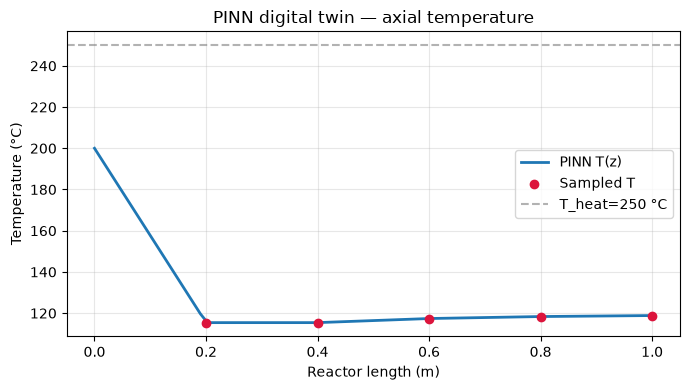

Digital twin stopped.


In [11]:
def _ask_float(prompt, default=None):
    hint = f" [{default}]" if default is not None else ""
    while True:
        raw = input(f"{prompt}{hint}: ").strip()
        if raw.lower() in {"q", "quit", "exit"}:
            return None
        if raw == "" and default is not None:
            return float(default)
        try:
            return float(raw)
        except ValueError:
            print("  Enter a number (or q to quit).")


def run_digital_twin_interactive():
    print("\n" + "=" * 62)
    print("  METHANOL REACTOR — PINN DIGITAL TWIN")
    print("  NN(z,u) + ODE residual loss + Excel data loss")
    print("=" * 62)
    print("  Press Enter for defaults. Type q to stop.\n")

    while True:
        T_in_C = _ask_float("Inlet temperature [°C]", default=float(df["T_in_C"].iloc[0]))
        if T_in_C is None:
            print("Digital twin stopped."); break
        P_in_bar_g = _ask_float("Inlet pressure [bar_g]", default=float(df["P_in_bar_g"].iloc[0]))
        T_heat_C = _ask_float(
            "Heating media temperature [C]",
            default=float(df["T_heat_C"].iloc[0]),  # Excel first-case default
        )
        if P_in_bar_g is None:
            print("Digital twin stopped."); break
        F_in_kgmole_h = _ask_float("Methanol molar flow [kgmole/h]", default=float(df["F_in_kgmole_h"].iloc[0]))
        if F_in_kgmole_h is None:
            print("Digital twin stopped."); break
        if F_in_kgmole_h <= 0:
            print("  Flow must be > 0.\n"); continue

        try:
            pred = predict_outputs(T_in_C, P_in_bar_g, T_heat_C, F_in_kgmole_h)
        except Exception as exc:
            print(f"  Prediction failed: {exc}\n"); continue

        print("\n" + "-" * 62)
        print("INPUTS")
        print(f"  T_in={T_in_C:.2f} °C | P_in={P_in_bar_g:.4f} bar_g | F={F_in_kgmole_h:.4f} kgmole/h")
        print(f"  Learned eta(u) ≈ {pred['eta']:.4e}")
        print("\nPINN TWIN OUTPUTS")
        for c in OUTPUT_COLS:
            print(f"  {c:16s}: {pred[c]:.4f}")
        print("-" * 62)

        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(pred["z_m"], pred["T_profile_C"], lw=2, label="PINN T(z)")
        ax.scatter(
            MEASUREMENT_POSITIONS_M,
            [pred[c] for c in TEMP_COLS],
            color="crimson", zorder=5, label="Sampled T",
        )
        ax.axhline(T_heat_C, color="gray", ls="--", alpha=0.6, label=f"T_heat={T_heat_C:.0f} °C")
        ax.set_xlabel("Reactor length (m)")
        ax.set_ylabel("Temperature (°C)")
        ax.set_title("PINN digital twin — axial temperature")
        ax.legend(); ax.grid(True, alpha=0.3)
        plt.tight_layout(); plt.show()

        again = input("\nRun another case? [Y/n]: ").strip().lower()
        if again in {"n", "no", "q", "quit"}:
            print("Digital twin stopped."); break


run_digital_twin_interactive()